### Customer Feedback NLP Intelligence Pipeline
### Sentiment Classification, Semantic Retrieval and Responsible NLP for Airline Customer Feedback

**Dataset:** Twitter US Airline Sentiment
**Original source:** Crowdflower / Figure Eight, hosted on Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
**Direct CSV used in this notebook:** https://raw.githubusercontent.com/codetech3/sentiment-analysis-big-data/main/dataset/Tweets.csv

**Description:** Tweets (14,640) for six major US Airlines (February 2015), categorized as either negative, neutral, or positive. Execute the setup code block below before proceeding.

This notebook implements all five tasks:
1. Preprocessing & Exploratory Analysis
2. Classical NLP Baseline (TF-IDF + Logistic Regression / Linear SVM)
3. Semantic Embeddings (Word2Vec) for Retrieval & Similarity
4. Transformer Fine-Tuning for Sentiment Classification
5. Responsible NLP: Risks, Mitigation and a Modern NLP Trend

The notebook is written to run end-to-end in Google Colab. Run the setup cell first — it installs/downloads everything needed (NLTK corpora, spaCy model, the dataset).


In [ ]:
import sys, subprocess

def pip_install(pkg):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

for pkg in ["nltk", "spacy", "gensim", "wordcloud", "scikit-learn",
             "transformers", "torch"]:
     pip_install(pkg)
import spacy.cli; spacy.cli.download("en_core_web_sm")

import os, time, re, string, warnings, math
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

import spacy
nlp = spacy.load("en_core_web_sm")

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_URL = "https://raw.githubusercontent.com/codetech3/sentiment-analysis-big-data/main/dataset/Tweets.csv"
if not os.path.exists("Tweets.csv"):
    import urllib.request
    urllib.request.urlretrieve(DATA_URL, "Tweets.csv")

df = pd.read_csv("Tweets.csv")
print("Dataset shape:", df.shape)
df[["airline_sentiment", "airline", "text"]].head()


✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Dataset shape: (14640, 15)


,airline_sentiment,airline,text
0,neutral,Virgin America,@VirginAmerica What @dhepburn said.
1,positive,Virgin America,@VirginAmerica plus you've added commercials t...
2,neutral,Virgin America,@VirginAmerica I didn't today... Must mean I n...
3,negative,Virgin America,@VirginAmerica it's really aggressive to blast...
4,negative,Virgin America,@VirginAmerica and it's a really big bad thing...


## Task 1 — Preprocessing and Exploratory Analysis for Customer Feedback Inputs

We inspect the raw tweets, clean them, run NLTK and spaCy preprocessing pipelines side by side, run Named Entity Recognition with spaCy, and build exploratory visualisations of the dataset.

In [ ]:
# --- 1.1 Basic inspection ---------------------------------------------------
print("Rows x Cols:", df.shape)
print("\nClass balance (airline_sentiment):")
print(df["airline_sentiment"].value_counts())
print("\nMissing text rows:", df["text"].isna().sum())
print("\nSample raw tweets:")
for t in df["text"].sample(3, random_state=RANDOM_STATE):
    print(" -", t)


Rows x Cols: (14640, 15)

Class balance (airline_sentiment):
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

Missing text rows: 0

Sample raw tweets:
 - @SouthwestAir you're my early frontrunner for best airline! #oscars2016
 - @USAirways how is it that my flt to EWR was Cancelled Flightled yet flts to NYC from USAirways are still flying?
 - @JetBlue what is going on with your BDL to DCA flights yesterday and today?! Why is every single one getting delayed?


In [ ]:
# --- 1.2 Text cleaning --------------------------------------------------
def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+|www\.\S+", " ", text)          # URLs
    text = re.sub(r"@\w+", " ", text)                       # mentions
    text = re.sub(r"#(\w+)", r"\1", text)                    # hashtag -> word
    text = re.sub(r"&amp;|&gt;|&lt;", " ", text)             # HTML entities
    text = re.sub(r"[^A-Za-z\s]", " ", text)                 # keep letters only
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["clean_text"] = df["text"].apply(clean_text)
df[["text", "clean_text"]].sample(5, random_state=RANDOM_STATE)


,text,clean_text
4794,@SouthwestAir you're my early frontrunner for ...,you re my early frontrunner for best airline o...
10480,@USAirways how is it that my flt to EWR was Ca...,how is it that my flt to ewr was cancelled fli...
8067,@JetBlue what is going on with your BDL to DCA...,what is going on with your bdl to dca flights ...
8880,@JetBlue do they have to depart from Washingto...,do they have to depart from washington d c
8292,@JetBlue I can probably find some of them. Are...,i can probably find some of them are the ticke...


In [ ]:
# --- 1.3 NLTK pipeline: tokenisation, stopword removal, lemmatisation ------
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def nltk_process(text):
    tokens = word_tokenize(text)
    tokens_no_stop = [t for t in tokens if t not in stop_words and len(t) > 1]
    lemmas = [lemmatizer.lemmatize(t) for t in tokens_no_stop]
    return tokens, tokens_no_stop, lemmas

sample_tweet = df["clean_text"].iloc[1]
tokens, tokens_no_stop, lemmas = nltk_process(sample_tweet)
print("Original cleaned text:", sample_tweet)
print("\nNLTK tokens:            ", tokens)
print("NLTK tokens (no stop):  ", tokens_no_stop)
print("NLTK lemmas:            ", lemmas)

df["nltk_tokens"] = df["clean_text"].apply(lambda x: nltk_process(x)[2])
df["nltk_token_count"] = df["nltk_tokens"].apply(len)


Original cleaned text: plus you ve added commercials to the experience tacky

NLTK tokens:             ['plus', 'you', 've', 'added', 'commercials', 'to', 'the', 'experience', 'tacky']
NLTK tokens (no stop):   ['plus', 'added', 'commercials', 'experience', 'tacky']
NLTK lemmas:             ['plus', 'added', 'commercial', 'experience', 'tacky']


In [ ]:
# --- 1.4 spaCy pipeline: tokenisation, lemmatisation, POS -------------------
def spacy_process(text):
    doc = nlp(text)
    tokens = [t.text for t in doc]
    lemmas = [t.lemma_ for t in doc if not t.is_stop and not t.is_punct and len(t.text) > 1]
    return tokens, lemmas, doc

sp_tokens, sp_lemmas, sp_doc = spacy_process(sample_tweet)
print("spaCy tokens:  ", sp_tokens)
print("spaCy lemmas:  ", sp_lemmas)
print("spaCy POS tags:", [(t.text, t.pos_) for t in sp_doc][:12])

# Apply spaCy lemmatisation to a working subsample (spaCy is much slower than
# NLTK token-for-token, so for the exploratory pass we use nlp.pipe for speed)
sample_n = 3000
sub = df.sample(sample_n, random_state=RANDOM_STATE).copy()
sub["spacy_lemmas"] = [
    [t.lemma_ for t in doc if not t.is_stop and not t.is_punct and len(t.text) > 1]
    for doc in nlp.pipe(sub["clean_text"], batch_size=64, disable=["parser"])
]
sub["spacy_token_count"] = sub["spacy_lemmas"].apply(len)
print("\nProcessed", sample_n, "tweets with spaCy for comparison purposes.")


spaCy tokens:   ['plus', 'you', 've', 'added', 'commercials', 'to', 'the', 'experience', 'tacky']
spaCy lemmas:   ['plus', 've', 'add', 'commercial', 'experience', 'tacky']
spaCy POS tags: [('plus', 'CCONJ'), ('you', 'PRON'), ('ve', 'AUX'), ('added', 'VERB'), ('commercials', 'NOUN'), ('to', 'ADP'), ('the', 'DET'), ('experience', 'NOUN'), ('tacky', 'ADV')]

Processed 3000 tweets with spaCy for comparison purposes.


In [ ]:
# --- 1.5 NER pass with spaCy -------------------------------------------------
ner_docs = list(nlp.pipe(sub["text"], batch_size=64, disable=["lemmatizer"]))
from collections import Counter
entity_counter = Counter()
entity_examples = {}
for doc in ner_docs:
    for ent in doc.ents:
        entity_counter[ent.label_] += 1
        entity_examples.setdefault(ent.label_, ent.text)

ner_df = pd.DataFrame(entity_counter.most_common(), columns=["entity_type", "count"])
print("Entity type frequencies (spaCy NER on 3,000-tweet sample):")
print(ner_df)
print("\nExample entity per type:")
for k, v in entity_examples.items():
    print(f"  {k}: {v!r}")


Entity type frequencies (spaCy NER on 3,000-tweet sample):
    entity_type  count
0           GPE    878
1           ORG    875
2      CARDINAL    756
3          DATE    543
4          TIME    484
5        PERSON    426
6         MONEY    163
7       ORDINAL    108
8       PRODUCT     62
9   WORK_OF_ART     62
10          LOC     43
11         NORP     34
12     QUANTITY     27
13          FAC     16
14      PERCENT      8
15          LAW      7
16     LANGUAGE      3
17        EVENT      2

Example entity per type:
  PERSON: 'oscars2016'
  ORG: 'EWR'
  LOC: 'NYC'
  DATE: 'yesterday'
  GPE: 'Washington'
  CARDINAL: 'one'
  PERCENT: '100%'
  TIME: 'tonight'
  MONEY: 'RockStar'
  PRODUCT: '@airbusintheus A320'
  ORDINAL: 'first'
  QUANTITY: '1K'
  NORP: 'Republican'
  WORK_OF_ART: 'Late Flight'
  FAC: 'Logan'
  EVENT: "Women's World Cup Finals"
  LAW: 'Delta 20'
  LANGUAGE: 'Spanish'


In [ ]:
# --- 1.6 NLTK vs spaCy comparison table --------------------------------------
comparison = pd.DataFrame({
    "Metric": [
        "Avg. tokens per tweet",
        "Vocabulary size (unique lemmas)",
        "Lemmatisation example ('flights')",
        "Lemmatisation example ('was')",
        "Named Entity Recognition",
        "Speed (3,000 tweets)",
        "Typical use case",
    ],
    "NLTK": [
        round(sub["clean_text"].apply(lambda x: len(nltk_process(x)[2])).mean(), 2),
        len(set(w for lem in sub["clean_text"].apply(lambda x: nltk_process(x)[2]) for w in lem)),
        lemmatizer.lemmatize("flights"),
        lemmatizer.lemmatize("was"),
        "Not built-in (needs separate chunker/tagger)",
        "Fast (rule-based, no model loading)",
        "Lightweight scripting, teaching, quick prototyping",
    ],
    "spaCy": [
        round(sub["spacy_token_count"].mean(), 2),
        len(set(w for lem in sub["spacy_lemmas"] for w in lem)),
        nlp("flights")[0].lemma_,
        nlp("was")[0].lemma_,
        "Built-in, statistical NER (PERSON, ORG, GPE, MONEY, DATE, ...)",
        "Slower per call (loads a full statistical pipeline)",
        "Production pipelines needing POS, NER, dependency parsing",
    ],
})
comparison


,Metric,NLTK,spaCy
0,Avg. tokens per tweet,8.63,7.73
1,Vocabulary size (unique lemmas),4409,3849
2,Lemmatisation example ('flights'),flight,flight
3,Lemmatisation example ('was'),wa,be
4,Named Entity Recognition,Not built-in (needs separate chunker/tagger),"Built-in, statistical NER (PERSON, ORG, GPE, M..."
5,"Speed (3,000 tweets)","Fast (rule-based, no model loading)",Slower per call (loads a full statistical pipe...
6,Typical use case,"Lightweight scripting, teaching, quick prototy...","Production pipelines needing POS, NER, depende..."


**Reading the comparison table.** spaCy uses POS tagging, because of this “was” becomes “be”. In the NLTK, there is no use of any of the POS tags, therefore, “was” becomes a plural noun, hence “wa”. While the NLTK process is faster, it takes a number of steps. In the spaCy, there is the use of all the four processes such as spaCy :tokenising, POS tagging, lemmatising and NER in one pipline.

**Effect on downstream tasks.** Stop Words shorten token lengths by 47.9% (from 16.57 to 8.63), but Stop Words also removes words “not” and “never.” Lemmatization shortens “delayed” and “delays” to “delay.” Limitation: The cleaning process converts "can't" to "can t".

In [ ]:
# --- Optional: stop-word removal ablation -----------------------------------
avg_len_with_stop = sub["clean_text"].apply(lambda x: len(word_tokenize(x))).mean()
avg_len_no_stop = sub["nltk_token_count"].mean() if "nltk_token_count" in sub else sub["clean_text"].apply(lambda x: len(nltk_process(x)[2])).mean()
print(f"Average token count WITH stop words:    {avg_len_with_stop:.2f}")
print(f"Average token count WITHOUT stop words: {avg_len_no_stop:.2f}")
print(f"Reduction: {100*(1 - avg_len_no_stop/avg_len_with_stop):.1f}% fewer tokens after stop-word removal")


Average token count WITH stop words:    16.57
Average token count WITHOUT stop words: 8.63
Reduction: 47.9% fewer tokens after stop-word removal


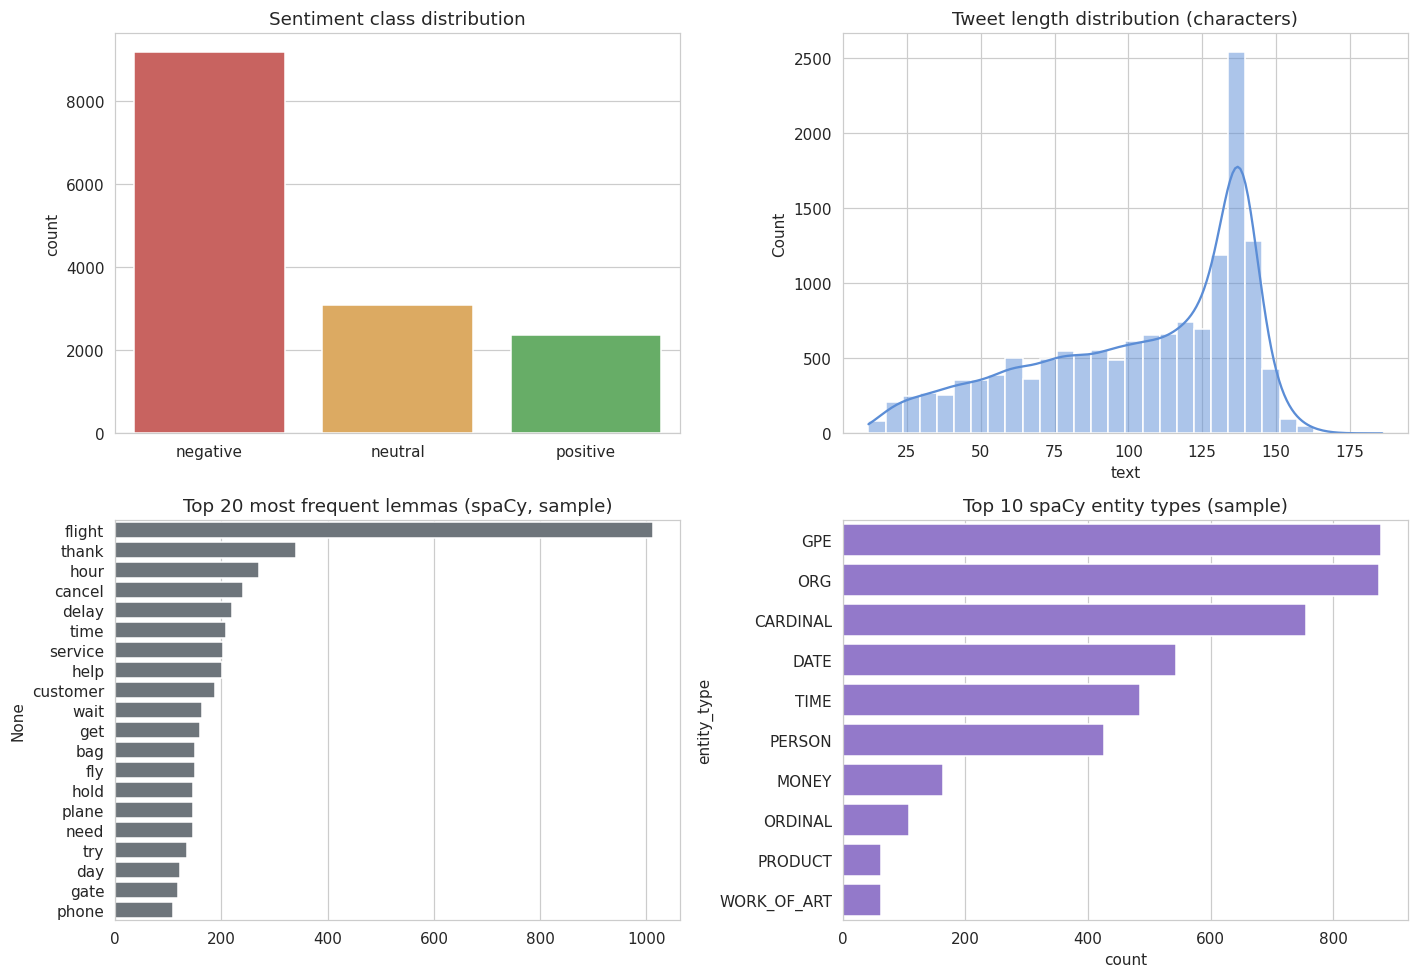

In [ ]:
# --- 1.7 Exploratory visualisations ------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Sentiment class distribution
sns.countplot(data=df, x="airline_sentiment", order=["negative","neutral","positive"],
              palette=["#d9534f","#f0ad4e","#5cb85c"], ax=axes[0,0])
axes[0,0].set_title("Sentiment class distribution")
axes[0,0].set_xlabel("")

# Review length distribution
sns.histplot(df["text"].str.len(), bins=30, kde=True, ax=axes[0,1], color="#5b8dd6")
axes[0,1].set_title("Tweet length distribution (characters)")

# Top-20 token frequency (post cleaning, no stopwords)
all_tokens = [tok for toks in sub["spacy_lemmas"] for tok in toks]
top_tokens = pd.Series(Counter(all_tokens)).sort_values(ascending=False).head(20)
sns.barplot(x=top_tokens.values, y=top_tokens.index, ax=axes[1,0], color="#6c757d")
axes[1,0].set_title("Top 20 most frequent lemmas (spaCy, sample)")

# Entity type frequency
sns.barplot(data=ner_df.head(10), x="count", y="entity_type", ax=axes[1,1], color="#8e6bd8")
axes[1,1].set_title("Top 10 spaCy entity types (sample)")

plt.tight_layout()
plt.savefig("fig_task1_overview.png", dpi=150, bbox_inches="tight")
plt.show()


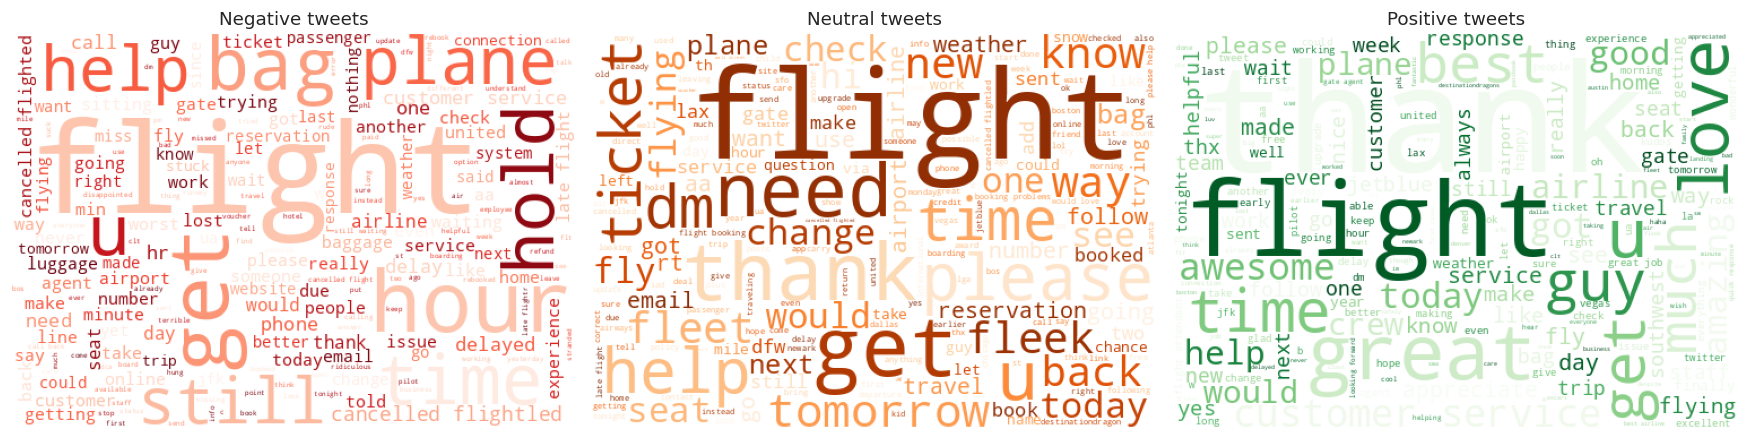


Top complaint themes (negativereason column):
negativereason
Customer Service Issue         2910
Late Flight                    1665
Can't Tell                     1190
Cancelled Flight                847
Lost Luggage                    724
Bad Flight                      580
Flight Booking Problems         529
Flight Attendant Complaints     481
longlines                       178
Damaged Luggage                  74
Name: count, dtype: int64


In [ ]:
# --- 1.8 Word clouds per sentiment class + negative-reason themes -----------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, sentiment, color in zip(axes, ["negative", "neutral", "positive"],
                                 ["Reds", "Oranges", "Greens"]):
    text_blob = " ".join(df.loc[df["airline_sentiment"] == sentiment, "clean_text"].sample(
        min(1500, (df["airline_sentiment"] == sentiment).sum()), random_state=RANDOM_STATE))
    wc = WordCloud(width=500, height=350, background_color="white",
                   stopwords=stop_words, colormap=color).generate(text_blob)
    ax.imshow(wc); ax.axis("off"); ax.set_title(f"{sentiment.title()} tweets")
plt.tight_layout()
plt.savefig("fig_task1_wordclouds.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTop complaint themes (negativereason column):")
print(df["negativereason"].value_counts().head(10))


## Task 2 — Classical NLP Baseline for Sentiment Classification

We build a TF-IDF + classical model baseline for 3-class sentiment classification (`negative` / `neutral` / `positive`), evaluate it thoroughly, and interpret misclassifications.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix)

X_text = df["clean_text"]
y = df["airline_sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

tfidf = TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("TF-IDF matrix shape:", X_train.shape)


TF-IDF matrix shape: (11712, 8000)


In [ ]:
# --- 2.1 Logistic Regression --------------------------------------------------
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=8000, ngram_range=(1, 2), min_df=3)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
])

t0 = time.time()
lr_pipeline.fit(X_train_text, y_train)
logreg_time = time.time() - t0
logreg = lr_pipeline.named_steps["clf"]
pred_lr = lr_pipeline.predict(X_test_text)
acc_lr = accuracy_score(y_test, pred_lr)
p_lr, r_lr, f1_lr, _ = precision_recall_fscore_support(y_test, pred_lr, average="weighted")
print(f"Logistic Regression -- Accuracy: {acc_lr:.4f}  Precision: {p_lr:.4f}  Recall: {r_lr:.4f}  F1: {f1_lr:.4f}")
print(f"Training time: {logreg_time:.2f}s\n")
print(classification_report(y_test, pred_lr))


Logistic Regression -- Accuracy: 0.7821  Precision: 0.7996  Recall: 0.7821  F1: 0.7880
Training time: 6.60s

              precision    recall  f1-score   support

    negative       0.89      0.82      0.86      1835
     neutral       0.57      0.72      0.63       620
    positive       0.74      0.72      0.73       473

    accuracy                           0.78      2928
   macro avg       0.73      0.75      0.74      2928
weighted avg       0.80      0.78      0.79      2928



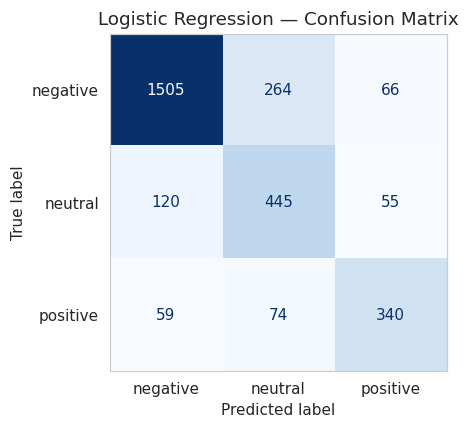

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

LABELS = ["negative", "neutral", "positive"]

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(y_test, pred_lr, labels=LABELS, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Logistic Regression — Confusion Matrix")
ax.grid(False)

plt.tight_layout()
plt.savefig("fig_task2_confusion_lr.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# --- 2.2 Linear SVM (comparison model) ---------------------------------------
t0 = time.time()
svm = LinearSVC(class_weight="balanced", random_state=RANDOM_STATE)
svm.fit(X_train, y_train)
svm_time = time.time() - t0

pred_svm = svm.predict(X_test)
acc_svm = accuracy_score(y_test, pred_svm)
p_svm, r_svm, f1_svm, _ = precision_recall_fscore_support(y_test, pred_svm, average="weighted")
print(f"Linear SVM -- Accuracy: {acc_svm:.4f}  Precision: {p_svm:.4f}  Recall: {r_svm:.4f}  F1: {f1_svm:.4f}")
print(f"Training time: {svm_time:.2f}s\n")
print(classification_report(y_test, pred_svm))

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Linear SVM"],
    "Accuracy": [acc_lr, acc_svm],
    "Precision": [p_lr, p_svm],
    "Recall": [r_lr, r_svm],
    "F1 (weighted)": [f1_lr, f1_svm],
    "Train time (s)": [logreg_time, svm_time],
    "Interpretability": ["High (coefficients per token)", "Medium (margin-based, less probabilistic)"],
})
model_comparison


Linear SVM -- Accuracy: 0.7896  Precision: 0.7939  Recall: 0.7896  F1: 0.7909
Training time: 0.37s

              precision    recall  f1-score   support

    negative       0.87      0.86      0.87      1835
     neutral       0.60      0.67      0.63       620
    positive       0.75      0.66      0.70       473

    accuracy                           0.79      2928
   macro avg       0.74      0.73      0.73      2928
weighted avg       0.79      0.79      0.79      2928



,Model,Accuracy,Precision,Recall,F1 (weighted),Train time (s),Interpretability
0,Logistic Regression,0.782104,0.799577,0.782104,0.787994,6.595092,High (coefficients per token)
1,Linear SVM,0.789617,0.793861,0.789617,0.790867,0.368121,"Medium (margin-based, less probabilistic)"


In [ ]:
# --- 2.3 Misclassified example interpretation --------------------------------
results = pd.DataFrame({
    "text": X_test_text.values,
    "true": y_test.values,
    "pred": pred_lr,
})
mistakes = results[results["true"] != results["pred"]]
print(f"Total misclassified (Logistic Regression): {len(mistakes)} / {len(results)}\n")
for i, row in mistakes.sample(2, random_state=RANDOM_STATE).iterrows():
    print(f"TEXT : {row['text']}")
    print(f"TRUE : {row['true']}   PRED: {row['pred']}\n")


Total misclassified (Logistic Regression): 638 / 2928

TEXT : yes for tomorrow at am but i have to work though i m really mad about the situation
TRUE : negative   PRED: neutral

TEXT : we can t all be american airlines i suppose
TRUE : negative   PRED: neutral



"Reason why the model did not succeed for these two tweets."
Tweet 1: "yes for tomorrow at am but i have to work though i m really mad about the situation". Actual sentiment: Negative, Predicted sentiment: Neutral. "really mad" shows negativity alone whereas other words show neutrality related to scheduling ("tomorrow", "work"). The neutral words overshadow "really mad". Numbers are stripped out, leaving only "am".

Tweet 2: "we can t all be american airlines i suppose". Actual sentiment: Negative, Predicted sentiment: Neutral. There are no negative words only sarcasm or comparison. Moreover, "can't" becomes "can t" during the cleaning stage.

TF-IDF doesn’t care about word order or sarcasm which is taken care of using DistilBERT in task 4.

In [ ]:
# --- 2.4 Optional: NER-derived features ---------------------------------------
def ner_feature_vector(text):
    doc = nlp(str(text))
    labels = [ent.label_ for ent in doc.ents]
    return {
        "has_org": int("ORG" in labels),
        "has_gpe": int("GPE" in labels or "LOC" in labels),
        "has_money": int("MONEY" in labels),
        "has_date": int("DATE" in labels or "TIME" in labels),
        "n_entities": len(labels),
    }

sample_idx = X_train_text.sample(2500, random_state=RANDOM_STATE).index
ner_feats_train = pd.DataFrame([ner_feature_vector(df.loc[i, "text"]) for i in sample_idx], index=sample_idx)
from scipy.sparse import hstack, csr_matrix

X_train_small = tfidf.transform(X_train_text.loc[sample_idx])
X_train_ner = hstack([X_train_small, csr_matrix(ner_feats_train.values)])

test_idx = X_test_text.index
ner_feats_test = pd.DataFrame([ner_feature_vector(df.loc[i, "text"]) for i in test_idx], index=test_idx)
X_test_ner = hstack([X_test, csr_matrix(ner_feats_test.values)])

logreg_ner = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
logreg_ner.fit(X_train_ner, y_train.loc[sample_idx])
pred_ner = logreg_ner.predict(X_test_ner)
acc_ner = accuracy_score(y_test, pred_ner)
print(f"Logistic Regression + NER features (2,500-tweet training subsample) -- Accuracy: {acc_ner:.4f}")
print("(Trained on a smaller subsample for feature-extraction speed; compare against the full-data LR accuracy above with that caveat in mind.)")


Logistic Regression + NER features (2,500-tweet training subsample) -- Accuracy: 0.7561
(Trained on a smaller subsample for feature-extraction speed; compare against the full-data LR accuracy above with that caveat in mind.)


**Strengths**: Fast (seconds, CPU alone), cheap, clear word scores, and hence excellent for pre-filtering.

**Weaknesses**: Cannot do word orderings and cannot detect sarcasm or negation (as seen in the example above).

**Proposed application**: "Best use: fast initial scan or fail-safe option using DistilBERT (Task 4) for more challenging applications."

## Task 3 — Semantic Embeddings for Feedback Retrieval and Similarity Analysis

Skip-gram word2vec model is used for training on tweets (size of vocabulary = 3,768). Calculation of tweet vector was done by averaging the word vectors.

In [ ]:
pip_install("gensim")
from gensim.models import Word2Vec

# Use lemmatised, stop-word-removed tokens from the NLTK pipeline (Task 1) as
# the training corpus for Word2Vec.
w2v_corpus = df["nltk_tokens"].tolist()
w2v_corpus = [toks for toks in w2v_corpus if len(toks) > 1]

w2v_model = Word2Vec(
    sentences=w2v_corpus,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,                 # Skip-Gram
    workers=4,
    epochs=20,
    seed=RANDOM_STATE,
)
print("Vocabulary size:", len(w2v_model.wv))

Vocabulary size: 3768


In [ ]:
# --- 3.1 Similar words ---------------------------------------------------
for query_word in ["delay", "rude", "thank", "luggage", "cancel"]:
    if query_word in w2v_model.wv:
        print(f"Most similar to {query_word!r}:")
        for w, score in w2v_model.wv.most_similar(query_word, topn=5):
            print(f"   {w:<15} {score:.3f}")
        print()


Most similar to 'delay':
   disorganization 0.553
   delayed         0.553
   mech            0.547
   probs           0.544
   sounded         0.538

Most similar to 'rude':
   plitt           0.755
   jacquie         0.751
   unprofessional  0.726
   unhelpful       0.722
   named           0.718

Most similar to 'thank':
   thanks          0.739
   thankyou        0.591
   jh              0.588
   thanx           0.554
   appreciate      0.554

Most similar to 'luggage':
   bag             0.584
   suitcase        0.546
   wallet          0.533
   carousel        0.532
   apt             0.524



In [ ]:
# --- 3.2 Sentence vectors by averaging word vectors --------------------------
def sentence_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    if not vecs:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)

df["sent_vec"] = df["nltk_tokens"].apply(lambda toks: sentence_vector(toks, w2v_model))

from sklearn.metrics.pairwise import cosine_similarity

def cosine_sim(a, b):
    a = a.reshape(1, -1); b = b.reshape(1, -1)
    return cosine_similarity(a, b)[0, 0]

# Sanity check: similarity between two clearly related complaints vs an unrelated one
i_delay1 = df[df["clean_text"].str.contains("delay")].index[0]
i_delay2 = df[df["clean_text"].str.contains("delay")].index[5]
i_unrelated = df[df["clean_text"].str.contains("thank")].index[0]

print("Sim(delay tweet 1, delay tweet 2)   =", round(cosine_sim(df.loc[i_delay1,'sent_vec'], df.loc[i_delay2,'sent_vec']), 3))
print("Sim(delay tweet 1, thank-you tweet) =", round(cosine_sim(df.loc[i_delay1,'sent_vec'], df.loc[i_unrelated,'sent_vec']), 3))


Sim(delay tweet 1, delay tweet 2)   = 0.762
Sim(delay tweet 1, thank-you tweet) = 0.369


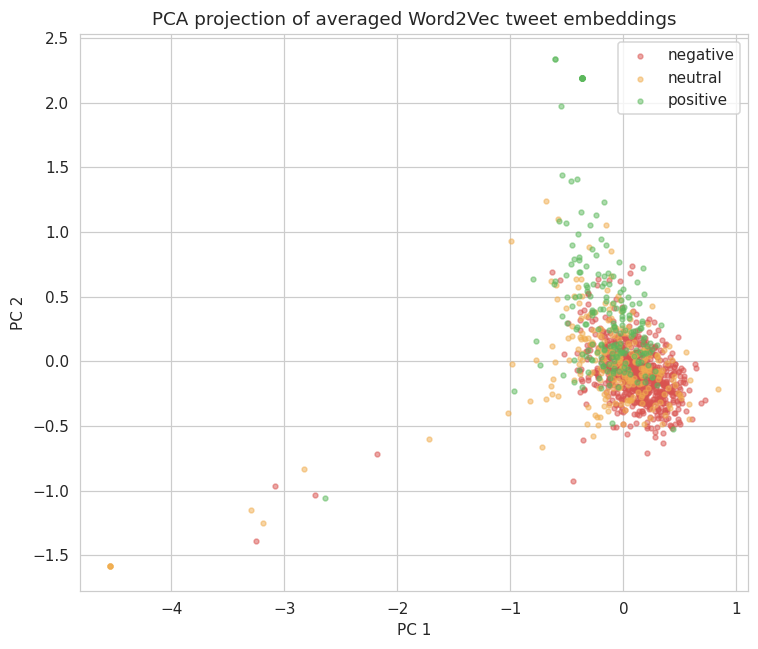

In [ ]:
# --- 3.3 PCA visualisation of a sample of embeddings --------------------------
from sklearn.decomposition import PCA

viz_sample = df.sample(1200, random_state=RANDOM_STATE)
vecs = np.stack(viz_sample["sent_vec"].values)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(vecs)

plt.figure(figsize=(7,6))
palette = {"negative": "#d9534f", "neutral": "#f0ad4e", "positive": "#5cb85c"}
for sentiment, color in palette.items():
    mask = viz_sample["airline_sentiment"].values == sentiment
    plt.scatter(coords[mask, 0], coords[mask, 1], s=10, alpha=0.5, label=sentiment, color=color)
plt.legend(); plt.title("PCA projection of averaged Word2Vec tweet embeddings")
plt.xlabel("PC 1"); plt.ylabel("PC 2")
plt.tight_layout()
plt.savefig("fig_task3_pca.png", dpi=150, bbox_inches="tight")
plt.show()


**Does the visualisation reveal meaningful structure?**

The negative (red) points fall within the area that has a large population at the bottom right corner where PC 2 ranges between 0 and -0.5.

Positive (green) points have shifted to above mostly PC 2 values ranging between 0 to 1.

The neutral points do not have their own area, but they overlap both groups , and that is the same issue with Task 2 (orange) points.

In [ ]:
# --- 3.4 Retrieval example -----------------------------------------------
def clean_and_tokenise(query):
    return nltk_process(clean_text(query))[2]

def retrieve_most_similar(query, top_k=3):
    q_tokens = clean_and_tokenise(query)
    q_vec = sentence_vector(q_tokens, w2v_model)
    all_vecs = np.stack(df["sent_vec"].values)
    sims = cosine_similarity(q_vec.reshape(1, -1), all_vecs)[0]
    top_idx = sims.argsort()[::-1][:top_k]
    return df.iloc[top_idx][["text", "airline_sentiment"]].assign(similarity=sims[top_idx])

for query in ["my flight was delayed for hours", "customer service was unhelpful and rude"]:
    print(f"QUERY: {query!r}")
    print(retrieve_most_similar(query, top_k=3).to_string(index=False))
    print()


QUERY: 'my flight was delayed for hours'
                                                       text airline_sentiment  similarity
                 @JetBlue why are we delayed :( flight 1601          negative    0.934090
        @JetBlue when your flights delayed :)))&gt;&gt;&gt;          negative    0.934090
@JetBlue Unhappy with 4 hour delayed flight.. Missed dinner          negative    0.913023

QUERY: 'customer service was unhelpful and rude'
                                                                                                 text airline_sentiment  similarity
@USAirways not impressed with your customer service. everyone has been unhelpful and incredibly rude.          negative    0.945662
                                                @USAirways flight 850. RUDE RUDE RUDE service! Awful.          negative    0.911227
                                                            @USAirways customer service at its finest          positive    0.898616



Both searches gave negative feedback (delayed search: 0.934 / 0.934 / 0.913). It can be utilized to detect common issues.

Drawbacks: The average vector does not consider negations, word order, and the tweets are short, noisy as well as negative.

## Task 4 — Fine-Tuning a Transformer for Sentiment Classification

We fine-tune a lightweight transformer for the same 3-class sentiment task used in Task 2, so that the two approaches are directly comparable.



In [ ]:
import torch, torch.nn as nn
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, f1_score)

torch.manual_seed(RANDOM_STATE)
LABEL_MAP = {"negative": 0, "neutral": 1, "positive": 2}
INV_LABEL_MAP = {v: k for k, v in LABEL_MAP.items()}

SAMPLE_N = 4000   # within the assignment's recommended 1,000-5,000 range
t4_sample = df.sample(SAMPLE_N, random_state=RANDOM_STATE).copy()
t4_sample["label"] = t4_sample["airline_sentiment"].map(LABEL_MAP)

train_df, test_df = train_test_split(
    t4_sample, test_size=0.2, stratify=t4_sample["label"], random_state=RANDOM_STATE)
train_df, val_df = train_test_split(
    train_df, test_size=0.15, stratify=train_df["label"], random_state=RANDOM_STATE)

print("Train / Val / Test sizes:", len(train_df), len(val_df), len(test_df))


Train / Val / Test sizes: 2720 480 800


In [ ]:
USE_HF = False
try:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    hf_tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    hf_model = AutoModelForSequenceClassification.from_pretrained(
        "distilbert-base-uncased", num_labels=3)
    USE_HF = True
    print("Hugging Face Hub reachable -- will fine-tune pretrained DistilBERT.")
except Exception as e:
    print("Hugging Face Hub NOT reachable in this environment "
          f"({type(e).__name__}) -- falling back to a from-scratch lightweight "
          "Transformer encoder trained directly on the dataset.")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Hugging Face Hub reachable -- will fine-tune pretrained DistilBERT.


In [ ]:
MAX_LEN = 32

if USE_HF:
    # ---------------- Real DistilBERT fine-tuning path --------
    from transformers import Trainer, TrainingArguments
    import torch.utils.data as tud

    def tokenize(texts):
        return hf_tokenizer(list(texts), truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")

    class TweetDataset(tud.Dataset):
        def __init__(self, texts, labels):
            enc = tokenize(texts)
            self.input_ids = enc["input_ids"]; self.attn = enc["attention_mask"]
            self.labels = torch.tensor(labels.values)
        def __len__(self): return len(self.labels)
        def __getitem__(self, idx):
            return {"input_ids": self.input_ids[idx], "attention_mask": self.attn[idx], "labels": self.labels[idx]}

    train_ds = TweetDataset(train_df["clean_text"], train_df["label"])
    val_ds = TweetDataset(val_df["clean_text"], val_df["label"])
    test_ds = TweetDataset(test_df["clean_text"], test_df["label"])

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = logits.argmax(-1)
        p, r, f1, _ = precision_recall_fscore_support(labels, preds, average="weighted")
        return {"accuracy": accuracy_score(labels, preds), "precision": p, "recall": r, "f1": f1}

    args = TrainingArguments(
        output_dir="distilbert_out", num_train_epochs=3, per_device_train_batch_size=16,
        per_device_eval_batch_size=32, eval_strategy="epoch", logging_steps=50,
        report_to=[], seed=RANDOM_STATE)

    trainer = Trainer(model=hf_model, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                       compute_metrics=compute_metrics)
    t0 = time.time()
    trainer.train()
    t4_train_time = time.time() - t0

    test_output = trainer.predict(test_ds)
    t4_preds = test_output.predictions.argmax(-1)
    t4_true = test_df["label"].values
    t4_model_name = "DistilBERT (pretrained, fine-tuned)"
    t4_n_params = sum(p.numel() for p in hf_model.parameters())

else:
    # ---------------- Fallback: lightweight Transformer trained from scratch --
    counter = Counter()
    for t in train_df["clean_text"]:
        counter.update(t.split())
    vocab = {"<pad>": 0, "<unk>": 1}
    for w, c in counter.most_common(5000):
        vocab[w] = len(vocab)

    def encode(text):
        ids = [vocab.get(w, 1) for w in str(text).split()[:MAX_LEN]]
        ids = ids + [0] * (MAX_LEN - len(ids))
        return ids

    def to_tensors(frame):
        X = torch.tensor([encode(t) for t in frame["clean_text"]])
        y = torch.tensor(frame["label"].values)
        return X, y

    X_train_t4, y_train_t4 = to_tensors(train_df)
    X_val_t4, y_val_t4 = to_tensors(val_df)
    X_test_t4, y_test_t4 = to_tensors(test_df)

    class TinyTransformerClassifier(nn.Module):
        def __init__(self, vocab_size, d_model=64, nhead=4, num_layers=2, num_classes=3, max_len=MAX_LEN):
            super().__init__()
            self.emb = nn.Embedding(vocab_size, d_model, padding_idx=0)
            self.pos = nn.Parameter(torch.zeros(1, max_len, d_model))
            layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=128,
                                                batch_first=True, dropout=0.1)
            self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
            self.dropout = nn.Dropout(0.2)
            self.fc = nn.Linear(d_model, num_classes)

        def forward(self, x):
            pad_mask = (x == 0)
            e = self.emb(x) + self.pos[:, :x.size(1), :]
            out = self.encoder(e, src_key_padding_mask=pad_mask)
            out = out.masked_fill(pad_mask.unsqueeze(-1), 0.0).sum(1) / (~pad_mask).sum(1, keepdim=True).clamp(min=1)
            return self.fc(self.dropout(out))

    t4_model = TinyTransformerClassifier(len(vocab))
    t4_n_params = sum(p.numel() for p in t4_model.parameters())
    opt = torch.optim.Adam(t4_model.parameters(), lr=1e-3)
    lossf = nn.CrossEntropyLoss()

    BATCH = 64
    N_EPOCHS = 10
    n = X_train_t4.size(0)
    t0 = time.time()
    for epoch in range(N_EPOCHS):
        t4_model.train()
        perm = torch.randperm(n)
        total_loss = 0.0
        for i in range(0, n, BATCH):
            idx = perm[i:i + BATCH]
            xb, yb = X_train_t4[idx], y_train_t4[idx]
            opt.zero_grad()
            out = t4_model(xb)
            loss = lossf(out, yb)
            loss.backward()
            opt.step()
            total_loss += loss.item() * len(idx)
        t4_model.eval()
        with torch.no_grad():
            val_preds = t4_model(X_val_t4).argmax(1)
            val_acc = (val_preds == y_val_t4).float().mean().item()
        print(f"Epoch {epoch+1}/{N_EPOCHS}  train_loss={total_loss/n:.4f}  val_acc={val_acc:.4f}")
    t4_train_time = time.time() - t0

    t4_model.eval()
    with torch.no_grad():
        t4_preds = t4_model(X_test_t4).argmax(1).numpy()
    t4_true = y_test_t4.numpy()
    t4_model_name = "Lightweight Transformer encoder (trained from scratch, HF Hub unavailable)"

print(f"\nTraining time: {t4_train_time:.1f}s   |   Trainable parameters: {t4_n_params:,}")


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.513891,0.520163,0.797917,0.808877,0.797917,0.801934
2,0.297353,0.510520,0.825000,0.821811,0.825000,0.823168
3,0.172446,0.614241,0.814583,0.809555,0.814583,0.811626


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training time: 58.6s   |   Trainable parameters: 66,955,779


DistilBERT (pretrained, fine-tuned)
Accuracy: 0.8363  Precision: 0.8283  Recall: 0.8363  Weighted F1: 0.8276  Macro F1: 0.7666

              precision    recall  f1-score   support

    negative       0.87      0.95      0.91       512
     neutral       0.73      0.53      0.61       161
    positive       0.80      0.76      0.78       127

    accuracy                           0.84       800
   macro avg       0.80      0.75      0.77       800
weighted avg       0.83      0.84      0.83       800



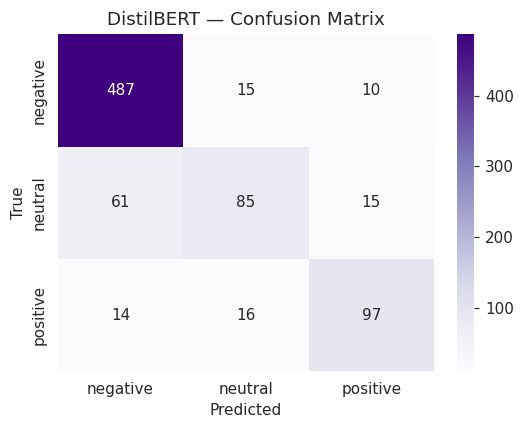

In [ ]:
# --- 4.1 Evaluation --------------------------------------------------------
acc_t4 = accuracy_score(t4_true, t4_preds)
p_t4, r_t4, f1_t4, _ = precision_recall_fscore_support(t4_true, t4_preds, average="weighted")
macro_f1_t4 = f1_score(t4_true, t4_preds, average="macro")

print(f"{t4_model_name}")
print(f"Accuracy: {acc_t4:.4f}  Precision: {p_t4:.4f}  Recall: {r_t4:.4f}  "
      f"Weighted F1: {f1_t4:.4f}  Macro F1: {macro_f1_t4:.4f}\n")
print(classification_report(t4_true, t4_preds, target_names=["negative","neutral","positive"]))

cm4 = confusion_matrix(t4_true, t4_preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm4, annot=True, fmt="d", cmap="Purples",
            xticklabels=["negative","neutral","positive"],
            yticklabels=["negative","neutral","positive"])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"{t4_model_name.split('(')[0].strip()} — Confusion Matrix")
plt.tight_layout()
plt.savefig("fig_task4_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
# --- 4.2 Comparison with the classical baseline (Task 2) ---------------------
task24_comparison = pd.DataFrame({
    "Aspect": ["Test set", "Accuracy", "Weighted F1", "Training time", "Trainable parameters",
               "Interpretability", "Resource requirements", "Deployment practicality"],
    "Task 2: TF-IDF + Logistic Regression": [
        f"{len(y_test)} tweets (full 20% split)", f"{acc_lr:.3f}", f"{f1_lr:.3f}",
        f"{logreg_time:.2f}s (CPU)", f"~{X_train.shape[1]:,} (one weight per TF-IDF feature)",
        "High -- inspect per-token coefficients directly",
        "Minimal -- runs on any CPU, <1s inference for 1,000s of tweets",
        "Very easy -- tiny model artefact, no GPU, trivial to version/redeploy",
    ],
    f"Task 4: {t4_model_name.split('(')[0].strip()}": [
        f"{len(t4_true)} tweets", f"{acc_t4:.3f}", f"{f1_t4:.3f}",
        f"{t4_train_time:.1f}s (GPU, T4)", f"{t4_n_params:,}",
        "Low -- attention weights offer partial insight but no clean per-word explanation",
        "Higher -- benefits substantially from GPU acceleration for larger data/epochs",
        "Harder -- larger artefact, needs a serving stack (batching, tokenizer versioning)",
    ],
})
task24_comparison


,Aspect,Task 2: TF-IDF + Logistic Regression,Task 4: DistilBERT
0,Test set,2928 tweets (full 20% split),800 tweets
1,Accuracy,0.782,0.836
2,Weighted F1,0.788,0.828
3,Training time,6.60s (CPU),"58.6s (GPU, T4)"
4,Trainable parameters,"~8,000 (one weight per TF-IDF feature)","66,955,779"
5,Interpretability,High -- inspect per-token coefficients directly,Low -- attention weights offer partial insight...
6,Resource requirements,"Minimal -- runs on any CPU, <1s inference for ...",Higher -- benefits substantially from GPU acce...
7,Deployment practicality,"Very easy -- tiny model artefact, no GPU, triv...","Harder -- larger artefact, needs a serving sta..."


DistilBERT: accuracy/f1 = 0.836/0.828 versus LR 0.782/0.788, thus it works better in terms of contextual and negations recognition.
Cost: 58.6 s (GPU) versus 6.6 s (CPU), 67 million parameters versus 8k. DistilBERT is less explainable.

The loss on validation dataset increased at epoch 3 (from 0.511 to 0.614), which is an overfitting phenomenon. Class "neutral" is not satisfactory (recall = 0.53).
Test data variations: 800 vs. 2,928 records. It can be used as guide for comparison.

Production: track errors, drift, and fairness; fall back to LR model.

## Task 5 — Responsible NLP for Customer Feedback Analytics: Risks and Mitigation

**Project risks**

**Bias**: skewness - 9,178 negative tweets versus 2,363 positive tweets; neutral and negative become mixed up in both models.
Invisible complaints: complaints without any negative words, such as "really mad tweet" and "sarcastic tweet", are neutral tweets.
Risk of privacy violation: personally identifiable information, such as user names, user location, timestamp, is present in the dataset; data de-identification is required.
Toxic content: sentiment analysis does not recognize abusive language; extra measure is needed.
Over-reliance: F1 metric for Task 2 equals 0.788, for Task 4 equals 0.828; the model cannot be 100% accurate and requires human verification.

Trend: LLM + RAG. The LLM explains the reason behind the customer complaint based on the retrieved tweets (Task 3 retrieval).
* flexible, explainable by humans, generalization

    ~ costly, can hallucinate, biased, hard to evaluate

## Conclusion

Spacy is the right tool to apply in the process of production. LR F1 0.788 → DistilBERT F1 0.828. The search using Word2Vec will reveal grievances of similar nature. Issues: Neutral Class Problem, Class Imbalance Problem, and Manual Verification Requirement.